# Data Analyst Professional Practical Exam Submission

**You can use any tool that you want to do your analysis and create visualizations. Use this template to write up your summary for submission.**

You can use any markdown formatting you wish. If you are not familiar with Markdown, read the [Markdown Guide](https://s3.amazonaws.com/talent-assets.datacamp.com/Markdown+Guide.pdf) before you start.


## Exploratory Analysis

In the past 6 weeks, around half of the customers were from email (n=7466), about one-third of the customers were from call (n=4962), and the remaining 17% customers were from email plus call (n=2572).

Email generated the highest total revenue, followed by email and call, and call. In short, Email attracted the highest number of customers and produced the most revenue.



The spread of revenue ranges from 30 to around 240 dollars, with a median revenue per sale of 90 dollars.


From the boxplot, the revenue range of email + call shows the widest spread and the highest central value. The majority of the revenue for email + call is 130 to 240 dollars, with a median of around 190 dollars. Email has a moderate range of 70 to 135 dollars, and call has the lowest range of 30 to 75 dollars.


Looking at the weekly revenue over time, it is found that email has a very high revenue in week 1. Although it declined sharply in week 2, the decrease flattened in week 3 (possibly due to a follow-up email). The weekly revenue for email is the highest from weeks 1 to 4.

There is a consistent growth in the revenue from Email + Call, peaks around week 5, and remains high in week 6. The revenue from calls is lower and mostly flat across the six weeks.



week                   int64
sales_method          object
customer_id           object
nb_sold                int64
revenue              float64
years_as_customer      int64
nb_site_visits         int64
state                 object
dtype: object
15000
[1, 2, 3, 4, 5, 6]
['Call', 'Email', 'Email + Call', 'em + call', 'email']
['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado', 'Connecticut', 'Delaware', 'Florida', 'Georgia', 'Hawaii', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana', 'Maine', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota', 'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Hampshire', 'New Jersey', 'New Mexico', 'New York', 'North Carolina', 'North Dakota', 'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania', 'Rhode Island', 'South Carolina', 'South Dakota', 'Tennessee', 'Texas', 'Utah', 'Vermont', 'Virginia', 'Washington', 'West Virginia', 'Wisconsin', 'Wyoming']
week: 0
sales_method: 0
customer_id: 0
nb_sold: 0


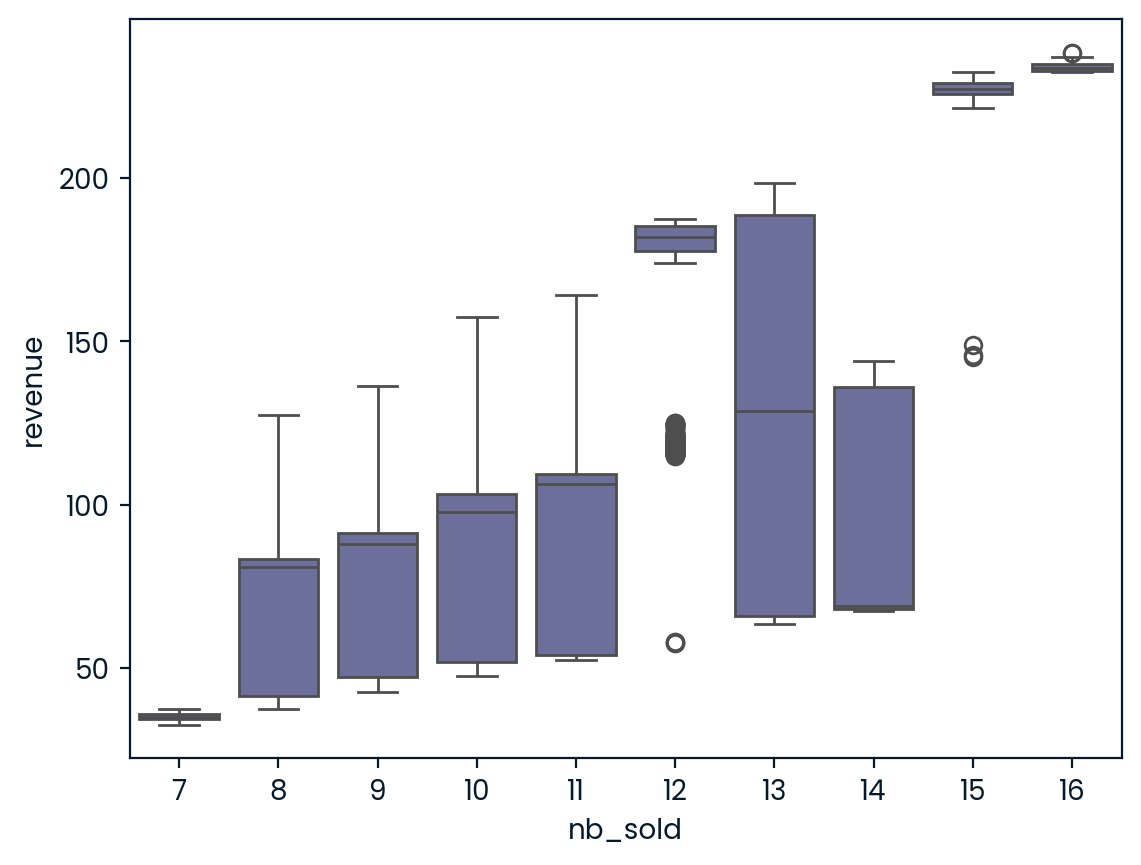

0
Rows: 15000, Columns: 8
Email           7466
Call            4962
Email + Call    2572
Name: sales_method, dtype: int64


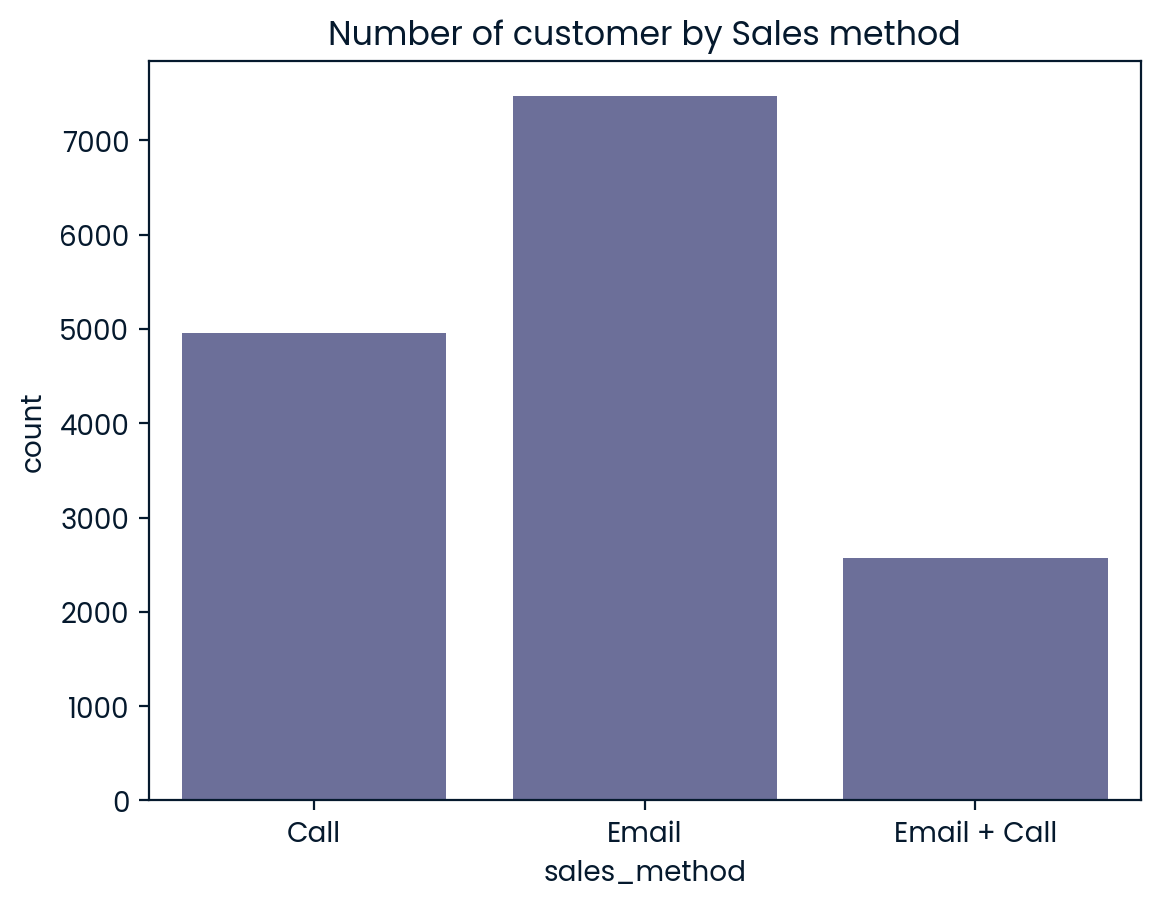

                 revenue
sales_method            
Call          244162.080
Email         725209.245
Email + Call  465921.730


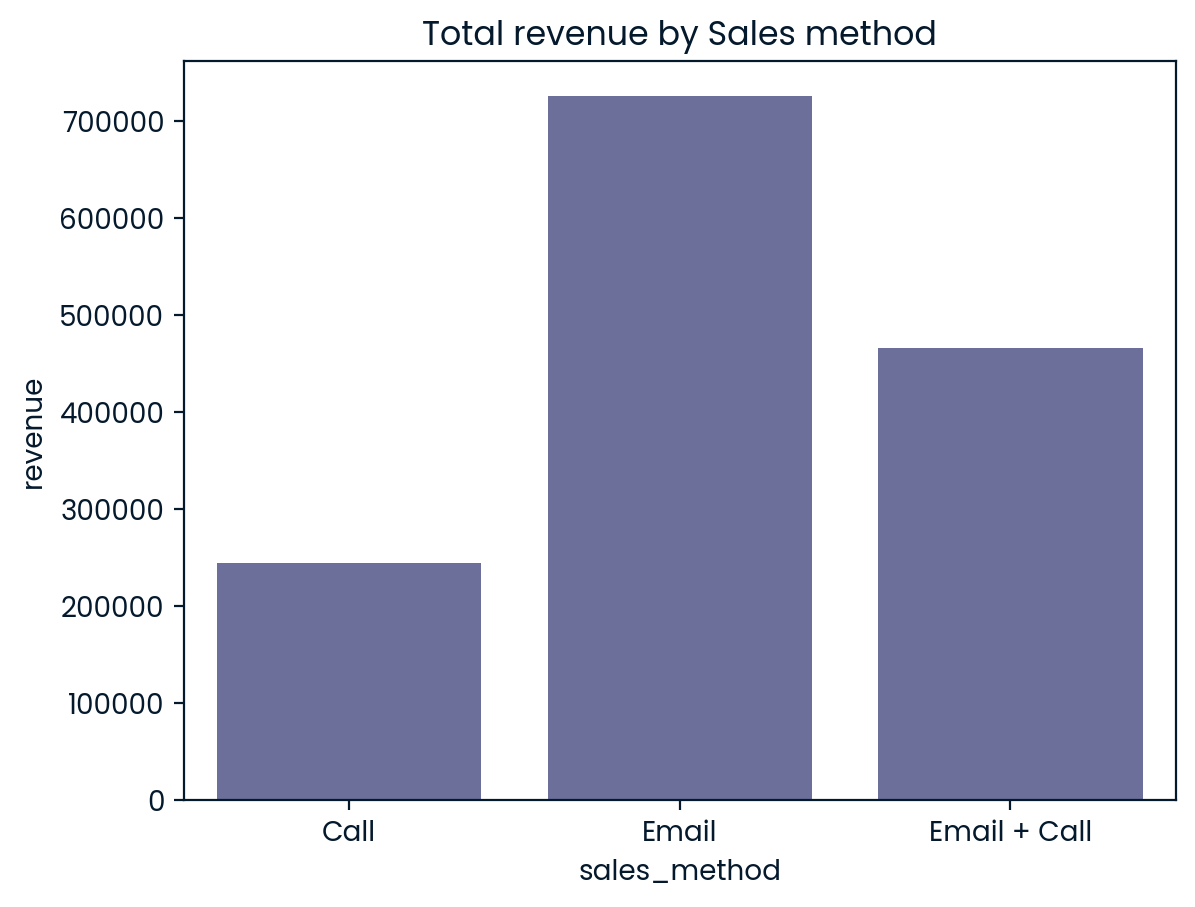

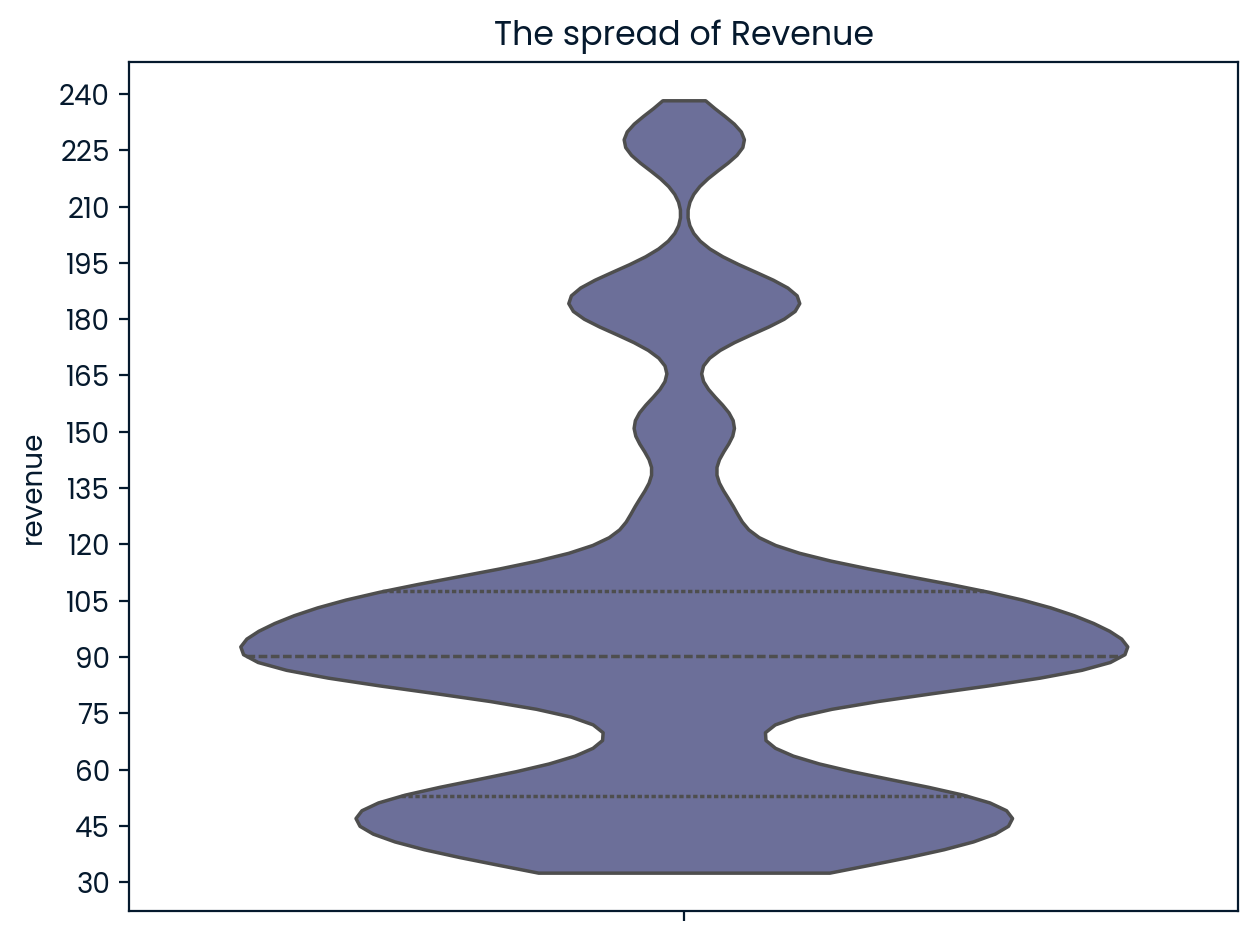

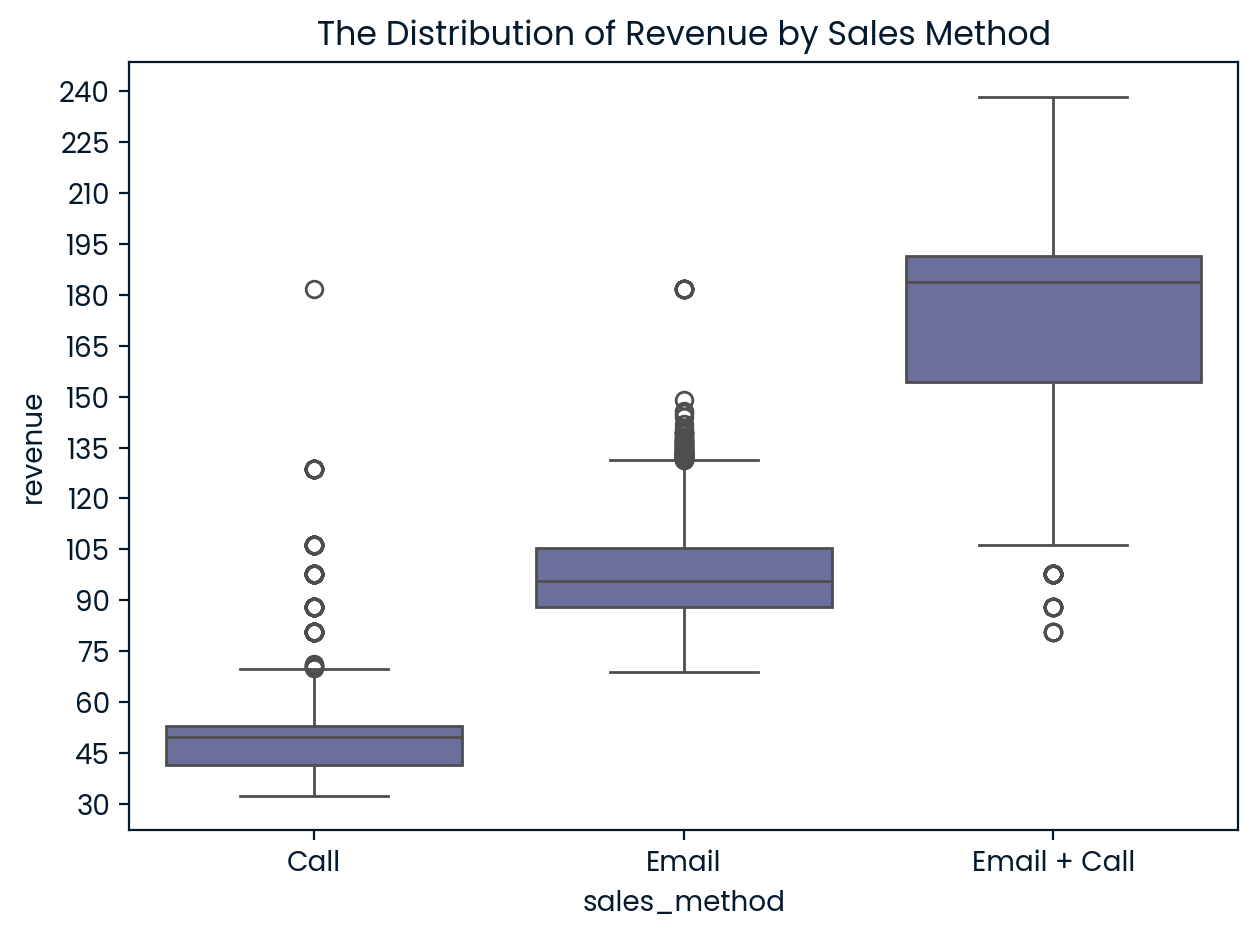

                      revenue
sales_method week            
Call         1      26835.925
             2      36397.880
             3      39042.775
             4      53669.130
             5      57438.890
             6      30777.480
Email        1     246025.650
             2     148710.330
             3     106653.640
             4     117148.570
             5      80963.900
             6      25707.155
Email + Call 1      18344.835
             2      29244.590
             3      52158.040
             4      89355.080
             5     144072.035
             6     132747.150


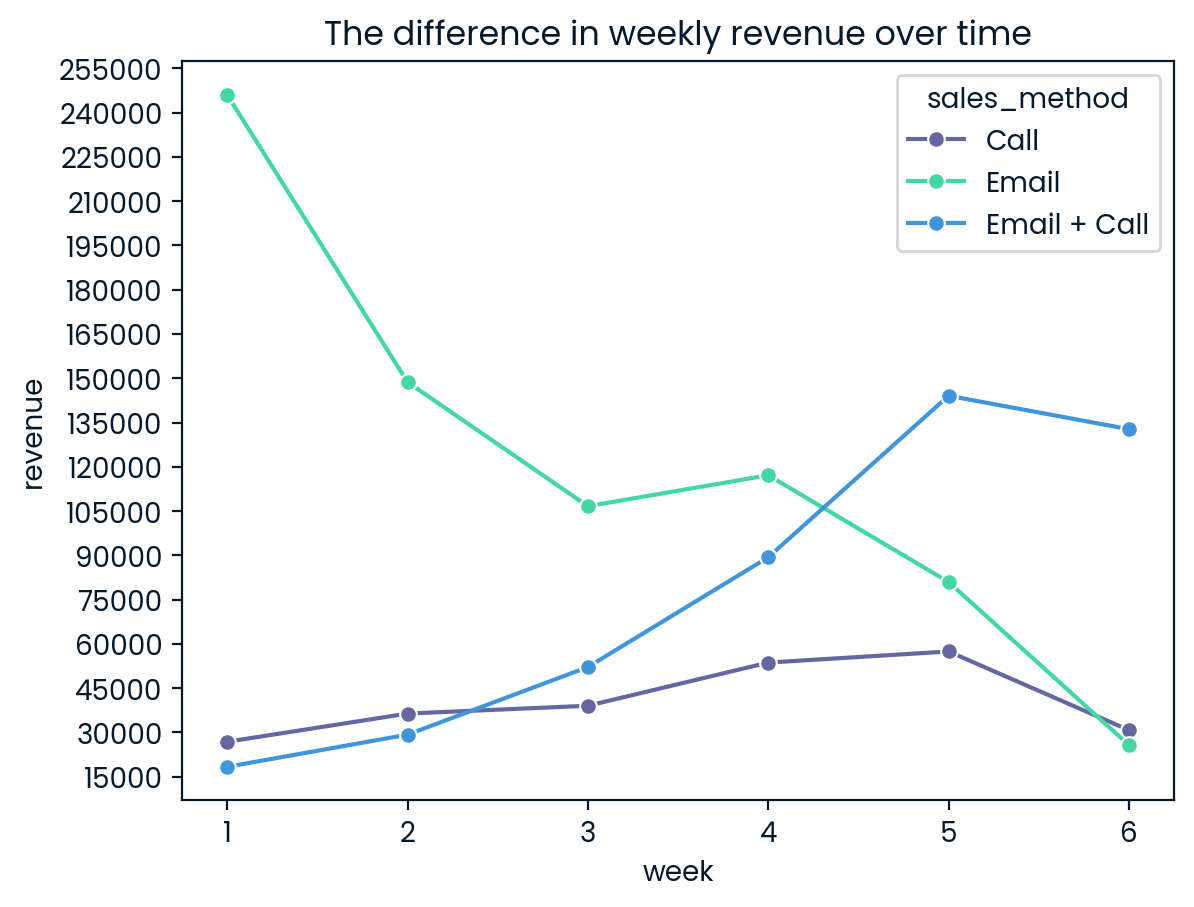

In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('product_sales.csv')
print(df.dtypes)

#Count the unique values of customer_id
print(df['customer_id'].nunique())
      
#Find unique values
columns = ['week', 'sales_method', 'state']
for x in columns:
    print(sorted(df[x].unique().tolist()))

#Find NA value
columns_NA = ['week', 'sales_method', 'customer_id', 'nb_sold', 'revenue', 'years_as_customer', 'nb_site_visits','state']
for x in columns_NA:
    print(f"{x}: {df[x].isna().sum()}")

#Check for non-negative value
columns_val = ['nb_sold', 'revenue', 'years_as_customer', 'nb_site_visits']
for x in columns_val:
    print(f"{x}: {df[x].min()}")

#Cleaning data in sales_method
df['sales_method'] = df['sales_method'].replace('em + call', 'Email + Call')
df['sales_method'] = df['sales_method'].replace('email', 'Email')

#Check again
df_valid = df['sales_method'].unique().tolist()
print(df_valid)

#Cannot drop the missing value with the threshold of 5% or less of total values
print(len(df['revenue']) * 0.05)

print(df['revenue'].isna().sum())

#boxplot suggested that imputing the median price based on the number of sold is a solid approach
revenue_boxplot = sns.boxplot(data=df, x="nb_sold", y="revenue")
plt.show()

#sub_group imputation
group_median = df.groupby('nb_sold')['revenue'].transform('median')

df['revenue'] = df['revenue'].fillna(group_median)

#check the missing value again in revenue column
print(df['revenue'].isna().sum())

rows, cols = df.shape
print(f"Rows: {rows}, Columns: {cols}")



#How many customers were there for each approach?
df_count_customer= df['sales_method'].value_counts()
print(df_count_customer)
Barchart = sns.countplot(data=df, x='sales_method',  order=['Call', 'Email', 'Email + Call'])
Barchart.set_title('Number of customer by Sales method')
plt.show()

#total revenue by method
df_count_customer= df.groupby(['sales_method']).agg({'revenue':'sum'})
print(df_count_customer)
Barchart_total_revenue = sns.barplot(data=df, x='sales_method', y='revenue', estimator=sum, ci=None, order=['Call', 'Email', 'Email + Call'])
Barchart_total_revenue.set_title('Total revenue by Sales method')
plt.show()

#What does the spread of the revenue look like overall? And for each method?
#Create a violin plot
from matplotlib.ticker import MaxNLocator
violinplot = sns.violinplot(y='revenue', data=df, inner='quartile', cut=0)
violinplot.yaxis.set_major_locator(MaxNLocator(nbins=20, integer=True))
violinplot.set_title('The spread of Revenue')
plt.tight_layout()
plt.show()

Distribution_by_methods = sns.boxplot(x='sales_method', y='revenue', data=df, order=['Call', 'Email', 'Email + Call'])
Distribution_by_methods.yaxis.set_major_locator(MaxNLocator(nbins=20, integer=True))
Distribution_by_methods.set_title('The Distribution of Revenue by Sales Method')
plt.tight_layout()
plt.show()

#Was there any difference in revenue over time for each of the methods?
df_revenue_sum= df.groupby(['sales_method', 'week']).agg({'revenue':'sum'})
print(df_revenue_sum) 

trend = sns.lineplot(x='week', y='revenue', data=df_revenue_sum,
hue='sales_method', marker='o', estimator=None)
trend.yaxis.set_major_locator(MaxNLocator(nbins=20, integer=True))
trend.set_title('The difference in weekly revenue over time')
plt.show()
 

